In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Ruta a tu archivo Excel
ruta_excel = "../data/Dataset Académico Parches en Servidores.xlsx"
print("Cargando pestañas...")

try:
    excel_file = pd.ExcelFile(ruta_excel)
    
    # header=3 toma la fila correcta con los encabezados
    servidores = pd.read_excel(excel_file, sheet_name=0, header=3)
    vulnerabilidades = pd.read_excel(excel_file, sheet_name=1, header=3)
    
    print("¡Pestañas cargadas exitosamente en 'servidores' y 'vulnerabilidades'!")

except Exception as e:
    print(f"Error al leer el archivo Excel: {e}")

Cargando pestañas...
Error al leer el archivo Excel: [Errno 2] No such file or directory: '../data/Dataset Académico Parches en Servidores.xlsx'


Normalización de Encabezados a Snake Case

In [3]:
def a_snake(columnas):
    return (columnas.astype(str).str.strip().str.lower()
            .str.replace(r"[^a-z0-9]+", "_", regex=True)
            .str.strip("_"))

servidores.columns = a_snake(servidores.columns)
vulnerabilidades.columns = a_snake(vulnerabilidades.columns)

print("Columnas Servidores:", servidores.columns.tolist())
print("\nColumnas Vulnerabilidades:", vulnerabilidades.columns.tolist())

NameError: name 'servidores' is not defined

In [ ]:
def normalizar_id(valor, prefijo, digitos):
    if pd.isna(valor):
        return None
    numero = "".join(c for c in str(valor) if c.isdigit())
    return f"{prefijo}-{int(numero):0{digitos}d}" if numero else None

servidores["serverid"] = servidores["serverid"].apply(lambda x: normalizar_id(x, "SRV", 4))
vulnerabilidades["serverid"] = vulnerabilidades["serverid"].apply(lambda x: normalizar_id(x, "SRV", 4))
vulnerabilidades["findingid"] = vulnerabilidades["findingid"].apply(lambda x: normalizar_id(x, "FND", 6))
vulnerabilidades["vulnerabilitytypeid"] = vulnerabilidades["vulnerabilitytypeid"].apply(lambda x: normalizar_id(x, "VTYPE", 4))

print("Muestra Servidores (serverid):", servidores["serverid"].head(3).tolist())
print("Muestra Vulnerabilidades (findingid):", vulnerabilidades["findingid"].head(3).tolist())

Muestra Servidores (serverid): ['SRV-0001', 'SRV-0002', 'SRV-0003']
Muestra Vulnerabilidades (findingid): ['FND-000001', 'FND-000002', 'FND-000003']


Texto normalizado

In [ ]:
NO_TOCAR = ["serverid", "findingid", "vulnerabilitytypeid", "vulnerability_volume_band"]

def limpiar_texto(df):
    for col in df.columns:
        if col in NO_TOCAR or df[col].dtype != "object":
            continue
        df[col] = (df[col].astype(str).str.strip().str.upper()
                   .str.replace(r"[\s\-]+", "_", regex=True)
                   .replace("NAN", pd.NA))
    return df

servidores = limpiar_texto(servidores)
vulnerabilidades = limpiar_texto(vulnerabilidades)

if "vulnerability_volume_band" in servidores.columns:
    servidores["vulnerability_volume_band"] = servidores["vulnerability_volume_band"].astype(str).str.strip().str.upper()

print("Texto normalizado correctamente.")

Texto normalizado correctamente.


Valores nulos

In [ ]:
relleno = {
    "exploitability_category": "NOT_IDENTIFIED",
    "malware_association": "NOT_IDENTIFIED",
    "reopen_band": "NONE",
}

# IDs nulos: se elimina la fila
servidores = servidores.dropna(subset=["serverid"])
vulnerabilidades = vulnerabilidades.dropna(subset=["findingid", "serverid"])

# Resto de columnas de texto: fillna según diccionario o "SIN_DATO"
for df in (servidores, vulnerabilidades):
    for col in df.columns:
        if df[col].isna().any() and col != "severity":
            df[col] = df[col].fillna(relleno.get(col, "SIN_DATO"))

print("Nulos restantes en servidores:", servidores.isna().sum().sum())
print("\nNulos restantes en vulnerabilidades (solo severity debería mostrar conteo si aplica):")
print(vulnerabilidades.isna().sum()[vulnerabilidades.isna().sum() > 0])

Nulos restantes en servidores: 0

Nulos restantes en vulnerabilidades (solo severity debería mostrar conteo si aplica):
Series([], dtype: int64)


Duplicados y eliminación de los duplicados

In [ ]:
antes_s, antes_v = len(servidores), len(vulnerabilidades)

servidores = servidores.drop_duplicates().drop_duplicates(subset="serverid")
vulnerabilidades = vulnerabilidades.drop_duplicates().drop_duplicates(subset="findingid")

print("Servidores duplicados eliminados:", antes_s - len(servidores))
print("Vulnerabilidades duplicadas eliminadas:", antes_v - len(vulnerabilidades))

# Guardado en CSV limpio listo para cargar a base de datos SQL
servidores.to_csv("servidores_limpio.csv", index=False, encoding="utf-8-sig")
vulnerabilidades.to_csv("vulnerabilidades_limpio.csv", index=False, encoding="utf-8-sig")
print("Archivos 'servidores_limpio.csv' y 'vulnerabilidades_limpio.csv' creados exitosamente.")

Servidores duplicados eliminados: 0
Vulnerabilidades duplicadas eliminadas: 0
Archivos 'servidores_limpio.csv' y 'vulnerabilidades_limpio.csv' creados exitosamente.


EDA

             ESTADÍSTICAS GENERALES
• Total Servidores Unicos: 246
• Total Vulnerabilidades Unicas: 3450
• Promedio de Vulnerabilidades por Servidor: 14.02


C:\Users\danyg\AppData\Local\Temp\ipykernel_4720\1244115191.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_vuln.values, y=top10_vuln.index, palette="viridis")


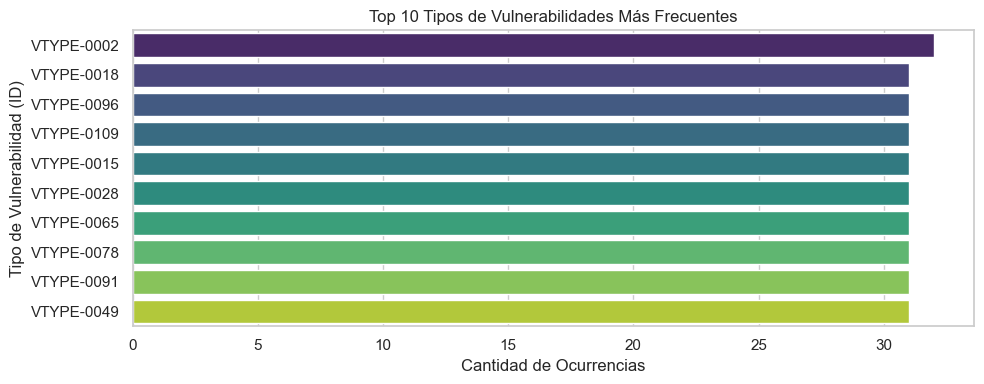

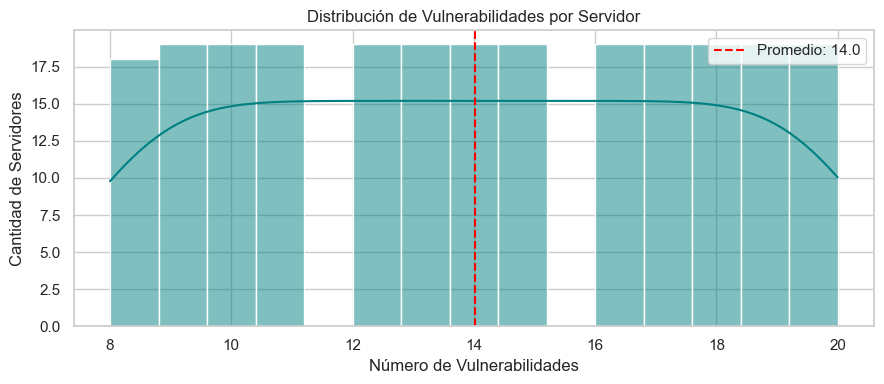

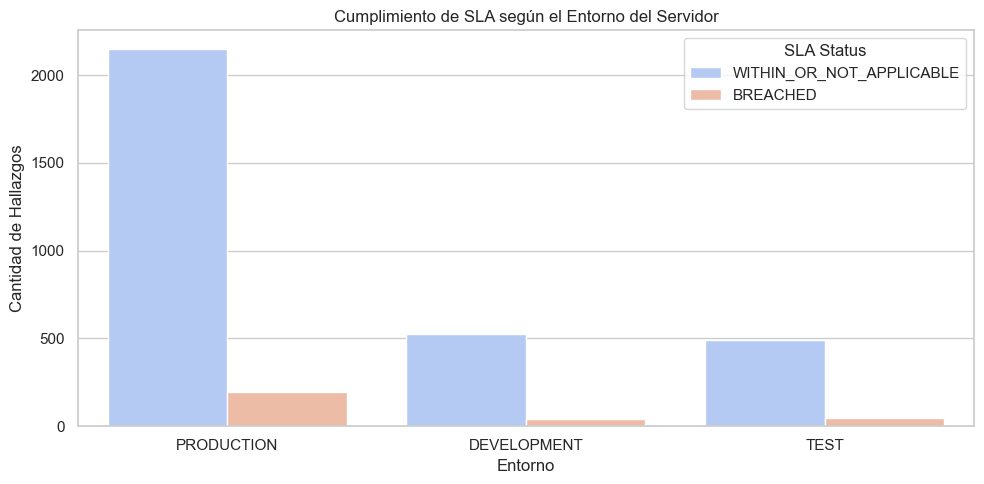

In [ ]:
# 1. MÉTRICAS GENERALES
total_srv = len(servidores)
total_vuln = len(vulnerabilidades)
promedio_vuln = round(total_vuln / total_srv, 2) if total_srv > 0 else 0

print("="*50)
print("             ESTADÍSTICAS GENERALES")
print("="*50)
print(f"• Total Servidores Unicos: {total_srv}")
print(f"• Total Vulnerabilidades Unicas: {total_vuln}")
print(f"• Promedio de Vulnerabilidades por Servidor: {promedio_vuln}")
print("="*50)

# 2. TOP 10 VULNERABILIDADES MÁS FRECUENTES
if "vulnerabilitytypeid" in vulnerabilidades.columns:
    top10_vuln = vulnerabilidades["vulnerabilitytypeid"].value_counts().head(10)
    plt.figure(figsize=(10, 4))
    sns.barplot(x=top10_vuln.values, y=top10_vuln.index, palette="viridis")
    plt.title("Top 10 Tipos de Vulnerabilidades Más Frecuentes")
    plt.xlabel("Cantidad de Ocurrencias")
    plt.ylabel("Tipo de Vulnerabilidad (ID)")
    plt.tight_layout()
    plt.show()

# 3. DISTRIBUCIÓN DE VULNERABILIDADES POR SERVIDOR
if "serverid" in vulnerabilidades.columns:
    vuln_por_srv = vulnerabilidades["serverid"].value_counts()
    plt.figure(figsize=(9, 4))
    sns.histplot(vuln_por_srv, bins=15, kde=True, color="teal")
    plt.axvline(vuln_por_srv.mean(), color="red", linestyle="--", label=f"Promedio: {vuln_por_srv.mean():.1f}")
    plt.title("Distribución de Vulnerabilidades por Servidor")
    plt.xlabel("Número de Vulnerabilidades")
    plt.ylabel("Cantidad de Servidores")
    plt.legend()
    plt.tight_layout()
    plt.show()

# 4. CRUCE Y ANÁLISIS DE CUMPLIMIENTO DE SLA POR ENTORNO
if "serverid" in servidores.columns and "serverid" in vulnerabilidades.columns:
    df_merged = pd.merge(vulnerabilidades, servidores, on="serverid", suffixes=("_vuln", "_srv"))
    
    col_env = [c for c in df_merged.columns if 'env' in c or 'environment' in c]
    col_sla = [c for c in df_merged.columns if 'sla' in c]
    
    if col_env and col_sla:
        plt.figure(figsize=(10, 5))
        sns.countplot(data=df_merged, x=col_env[0], hue=col_sla[0], palette="coolwarm")
        plt.title("Cumplimiento de SLA según el Entorno del Servidor")
        plt.xlabel("Entorno")
        plt.ylabel("Cantidad de Hallazgos")
        plt.legend(title="SLA Status")
        plt.tight_layout()
        plt.show()

In [ ]:
# 1. Validación de Severity (entre 1 y 5)
vulnerabilidades["severity"] = pd.to_numeric(vulnerabilidades["severity"], errors="coerce")
fuera = vulnerabilidades["severity"].notna() & ~vulnerabilidades["severity"].between(1, 5)
print("Severity fuera de 1-5:", fuera.sum())

# 2. Integridad referencial: Ajustado a 'serverid'
huerfanos = set(vulnerabilidades["serverid"]) - set(servidores["serverid"])
print("Hallazgos con serverid inexistente:", len(huerfanos))

# 3. Conteos finales de dimensiones
print("\nServidores:", servidores.shape, "| Vulnerabilidades:", vulnerabilidades.shape)

# 4. Función para inspección visual de categorías
def valores_unicos(df, titulo):
    print(f"\n--- VALORES ÚNICOS: {titulo} ---")
    for col in df.columns:
        unicos = df[col].unique()
        print(f"• {col} ({len(unicos)} únicos): {unicos[:5]}")

# Ejecución de la inspección
valores_unicos(servidores, "SERVIDORES (limpio)")
valores_unicos(vulnerabilidades, "VULNERABILIDADES (limpio)")

Severity fuera de 1-5: 0
Hallazgos con serverid inexistente: 0

Servidores: (246, 17) | Vulnerabilidades: (3450, 20)

--- VALORES ÚNICOS: SERVIDORES (limpio) ---
• serverid (246 únicos): <ArrowStringArray>
['SRV-0001', 'SRV-0002', 'SRV-0003', 'SRV-0004', 'SRV-0005']
Length: 5, dtype: str
• osfamily (5 únicos): <ArrowStringArray>
['WINDOWS_SERVER', 'LINUX_SERVER', 'UNIX_SERVER', 'OTHER_SERVER',
 'HYPERVISOR']
Length: 5, dtype: str
• oslifecycle (3 únicos): <ArrowStringArray>
['EOL', 'EOL_EOS', 'SUPPORTED']
Length: 3, dtype: str
• infrastructuretype (2 únicos): <ArrowStringArray>
['CLOUD', 'ON_PREM']
Length: 2, dtype: str
• assettype (3 únicos): <ArrowStringArray>
['VIRTUAL_MACHINE', 'HYPERVISOR', 'PHYSICAL_SERVER']
Length: 3, dtype: str
• functionalrole (9 únicos): <ArrowStringArray>
['GENERAL_INFRASTRUCTURE',          'ERP_ANALYTICS',               'DATABASE',
         'ERP_GOVERNANCE',        'WEB_APPLICATION']
Length: 5, dtype: str
• environment (3 únicos): <ArrowStringArray>
['PRODU

Exportar

In [ ]:
from pathlib import Path

# 1. Aserción de seguridad (detiene la ejecución si existen huérfanos)
assert len(huerfanos) == 0, f"Hay {len(huerfanos)} hallazgos huérfanos: corrígelos antes de exportar"

# 2. Definir la ruta de la carpeta única
carpeta_destino = Path("tablas_limpias")
carpeta_destino.mkdir(parents=True, exist_ok=True)

# 3. Exportar únicamente los dos archivos CSV requeridos
servidores.to_csv(carpeta_destino / "tabla1_s_clean.csv", index=False, encoding="utf-8-sig")
vulnerabilidades.to_csv(carpeta_destino / "tabla2_v_clean.csv", index=False, encoding="utf-8-sig")

print(f"Archivos exportados exitosamente en la carpeta: '{carpeta_destino.resolve()}'")

Archivos exportados exitosamente en la carpeta: 'C:\Users\danyg\OneDrive\Documentos\GitHub\Reto-FEMSA\tablas_limpias'
